In [1]:
# ==========================================
# Import Libraries
# ==========================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("Libraries Imported Successfully")

Libraries Imported Successfully


In [2]:
# ==========================================
# Load Dataset
# ==========================================

df = pd.read_csv("dataset-water-realistic.csv")

print("Dataset Loaded Successfully")

print("Shape :", df.shape)

df.head()

Dataset Loaded Successfully
Shape : (30000, 23)


,Date,State,District,Year,Month,Season,Rainfall_mm,Temperature_C,Humidity_pct,Reservoir_Level_pct,...,Water_Consumption_MLD,pH,Turbidity_NTU,Dissolved_Oxygen_mgL,TDS_mgL,Conductivity_uScm,BOD_mgL,Nitrate_mgL,Water_Availability,Water_Quality
0,2010-01-01,Telangana,Nizamabad,2010.0,1.0,Winter,29.04,20.63,62.63,37.44,...,68.82,7.40,2.78,7.74,228.76,400.55,3.24,2.54,Low,Moderate
1,2010-01-01,Karnataka,Mangaluru,2010.0,1.0,Winter,48.32,18.62,62.94,54.38,...,90.31,7.47,3.40,7.83,211.14,396.51,NaN,2.77,Low,Moderate
2,2010-01-01,Karnataka,Bengaluru,2010.0,1.0,Winter,22.35,21.30,64.34,33.89,...,74.80,7.11,1.91,7.91,186.84,391.46,2.84,2.46,Low,Good
3,2010-01-01,Tamil Nadu,Madurai,2010.0,1.0,Winter,34.97,21.59,55.44,54.35,...,80.68,7.18,2.67,8.51,201.03,411.87,3.31,2.57,Low,Good
4,2010-01-01,Karnataka,Mysuru,2010.0,1.0,Winter,44.39,17.25,54.91,46.71,...,84.90,7.22,3.51,8.82,180.89,394.37,3.51,2.61,Low,Moderate


In [3]:
# ==========================================
# Dataset Information
# ==========================================

print("Shape")
print(df.shape)

print("\nColumns")
print(df.columns.tolist())

print("\nData Types")
print(df.dtypes)

print("\nMissing Values")
print(df.isnull().sum())

print("\nDuplicate Rows")
print(df.duplicated().sum())

Shape
(30000, 23)

Columns
['Date', 'State', 'District', 'Year', 'Month', 'Season', 'Rainfall_mm', 'Temperature_C', 'Humidity_pct', 'Reservoir_Level_pct', 'Groundwater_Level_m', 'River_Flow_m3s', 'Population', 'Water_Consumption_MLD', 'pH', 'Turbidity_NTU', 'Dissolved_Oxygen_mgL', 'TDS_mgL', 'Conductivity_uScm', 'BOD_mgL', 'Nitrate_mgL', 'Water_Availability', 'Water_Quality']

Data Types
Date                      object
State                     object
District                  object
Year                     float64
Month                    float64
Season                    object
Rainfall_mm              float64
Temperature_C            float64
Humidity_pct             float64
Reservoir_Level_pct      float64
Groundwater_Level_m      float64
River_Flow_m3s           float64
Population               float64
Water_Consumption_MLD    float64
pH                       float64
Turbidity_NTU            float64
Dissolved_Oxygen_mgL     float64
TDS_mgL                  float64
Conductivity_uS

In [4]:
print(df["Water_Quality"].value_counts())

print(df["Water_Quality"].value_counts(normalize=True)*100)

Poor         11958
Moderate      9926
Good          8010
Excellent      106
Name: Water_Quality, dtype: int64
Poor         39.860000
Moderate     33.086667
Good         26.700000
Excellent     0.353333
Name: Water_Quality, dtype: float64


In [5]:
# ==========================================
# Missing Values Analysis
# ==========================================

missing = df.isnull().sum()

missing = pd.DataFrame({
    "Column": missing.index,
    "Missing Values": missing.values,
    "Percentage": (missing.values / len(df)) * 100
})

missing = missing[missing["Missing Values"] > 0]

print(missing)

print("\nTotal Missing Values:", df.isnull().sum().sum())

                   Column  Missing Values  Percentage
3                    Year             916    3.053333
4                   Month             901    3.003333
6             Rainfall_mm             892    2.973333
7           Temperature_C             883    2.943333
8            Humidity_pct             896    2.986667
9     Reservoir_Level_pct             895    2.983333
10    Groundwater_Level_m             869    2.896667
11         River_Flow_m3s             904    3.013333
12             Population             941    3.136667
13  Water_Consumption_MLD             878    2.926667
14                     pH             889    2.963333
15          Turbidity_NTU             915    3.050000
16   Dissolved_Oxygen_mgL             948    3.160000
17                TDS_mgL             884    2.946667
18      Conductivity_uScm             878    2.926667
19                BOD_mgL             921    3.070000
20            Nitrate_mgL             878    2.926667

Total Missing Values: 15288

In [6]:
# ==========================================
# Handle Missing Values
# ==========================================

from sklearn.impute import SimpleImputer

# Numerical columns
num_cols = df.select_dtypes(include=["int64", "float64"]).columns

# Categorical columns
cat_cols = df.select_dtypes(include=["object"]).columns

# Median imputation for numerical data
num_imputer = SimpleImputer(strategy="median")
df[num_cols] = num_imputer.fit_transform(df[num_cols])

# Mode imputation for categorical data
cat_imputer = SimpleImputer(strategy="most_frequent")
df[cat_cols] = cat_imputer.fit_transform(df[cat_cols])

print("Missing Values After Imputation:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values After Imputation:
Date                     0
State                    0
District                 0
Year                     0
Month                    0
Season                   0
Rainfall_mm              0
Temperature_C            0
Humidity_pct             0
Reservoir_Level_pct      0
Groundwater_Level_m      0
River_Flow_m3s           0
Population               0
Water_Consumption_MLD    0
pH                       0
Turbidity_NTU            0
Dissolved_Oxygen_mgL     0
TDS_mgL                  0
Conductivity_uScm        0
BOD_mgL                  0
Nitrate_mgL              0
Water_Availability       0
Water_Quality            0
dtype: int64

Total Missing Values: 0


In [7]:
# ==========================================
# Remove Duplicate Records
# ==========================================

print("Shape Before Removing Duplicates:", df.shape)

duplicates = df.duplicated().sum()
print("Duplicate Rows:", duplicates)

# Remove duplicates
df.drop_duplicates(inplace=True)

print("Shape After Removing Duplicates:", df.shape)

Shape Before Removing Duplicates: (30000, 23)
Duplicate Rows: 0
Shape After Removing Duplicates: (30000, 23)


In [8]:
# ==========================================
# Convert Date Column
# ==========================================

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print(df["Date"].head())

print("\nDate Range")
print("Start Date :", df["Date"].min())
print("End Date   :", df["Date"].max())

0   2010-01-01
1   2010-01-01
2   2010-01-01
3   2010-01-01
4   2010-01-01
Name: Date, dtype: datetime64[ns]

Date Range
Start Date : 2010-01-01 00:00:00
End Date   : 2025-12-31 00:00:00


In [9]:
# ==========================================
# Dataset Information
# ==========================================

print("Shape :", df.shape)

print("\nData Types")
print(df.dtypes)

print("\nMissing Values")
print(df.isnull().sum().sum())

print("\nDuplicate Rows")
print(df.duplicated().sum())

Shape : (30000, 23)

Data Types
Date                     datetime64[ns]
State                            object
District                         object
Year                            float64
Month                           float64
Season                           object
Rainfall_mm                     float64
Temperature_C                   float64
Humidity_pct                    float64
Reservoir_Level_pct             float64
Groundwater_Level_m             float64
River_Flow_m3s                  float64
Population                      float64
Water_Consumption_MLD           float64
pH                              float64
Turbidity_NTU                   float64
Dissolved_Oxygen_mgL            float64
TDS_mgL                         float64
Conductivity_uScm               float64
BOD_mgL                         float64
Nitrate_mgL                     float64
Water_Availability               object
Water_Quality                    object
dtype: object

Missing Values
0

Duplicate Rows


In [10]:
# ==========================================
# Water Quality Distribution
# ==========================================

print(df["Water_Quality"].value_counts())

print("\nPercentage Distribution")

print(
    round(
        df["Water_Quality"].value_counts(normalize=True) * 100,
        2
    )
)

Poor         11958
Moderate      9926
Good          8010
Excellent      106
Name: Water_Quality, dtype: int64

Percentage Distribution
Poor         39.86
Moderate     33.09
Good         26.70
Excellent     0.35
Name: Water_Quality, dtype: float64


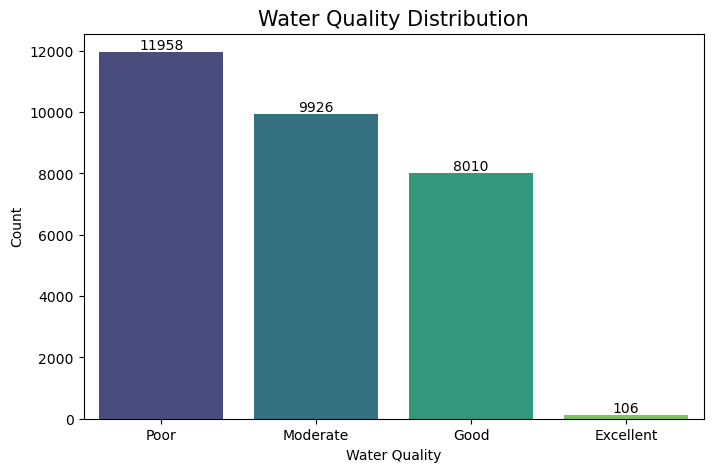

In [11]:
# ==========================================
# Water Quality Distribution
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

ax = sns.countplot(
    data=df,
    x="Water_Quality",
    order=df["Water_Quality"].value_counts().index,
    palette="viridis"
)

for p in ax.patches:
    ax.annotate(
        f"{int(p.get_height())}",
        (p.get_x() + p.get_width()/2, p.get_height()),
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.title("Water Quality Distribution", fontsize=15)
plt.xlabel("Water Quality")
plt.ylabel("Count")
plt.show()

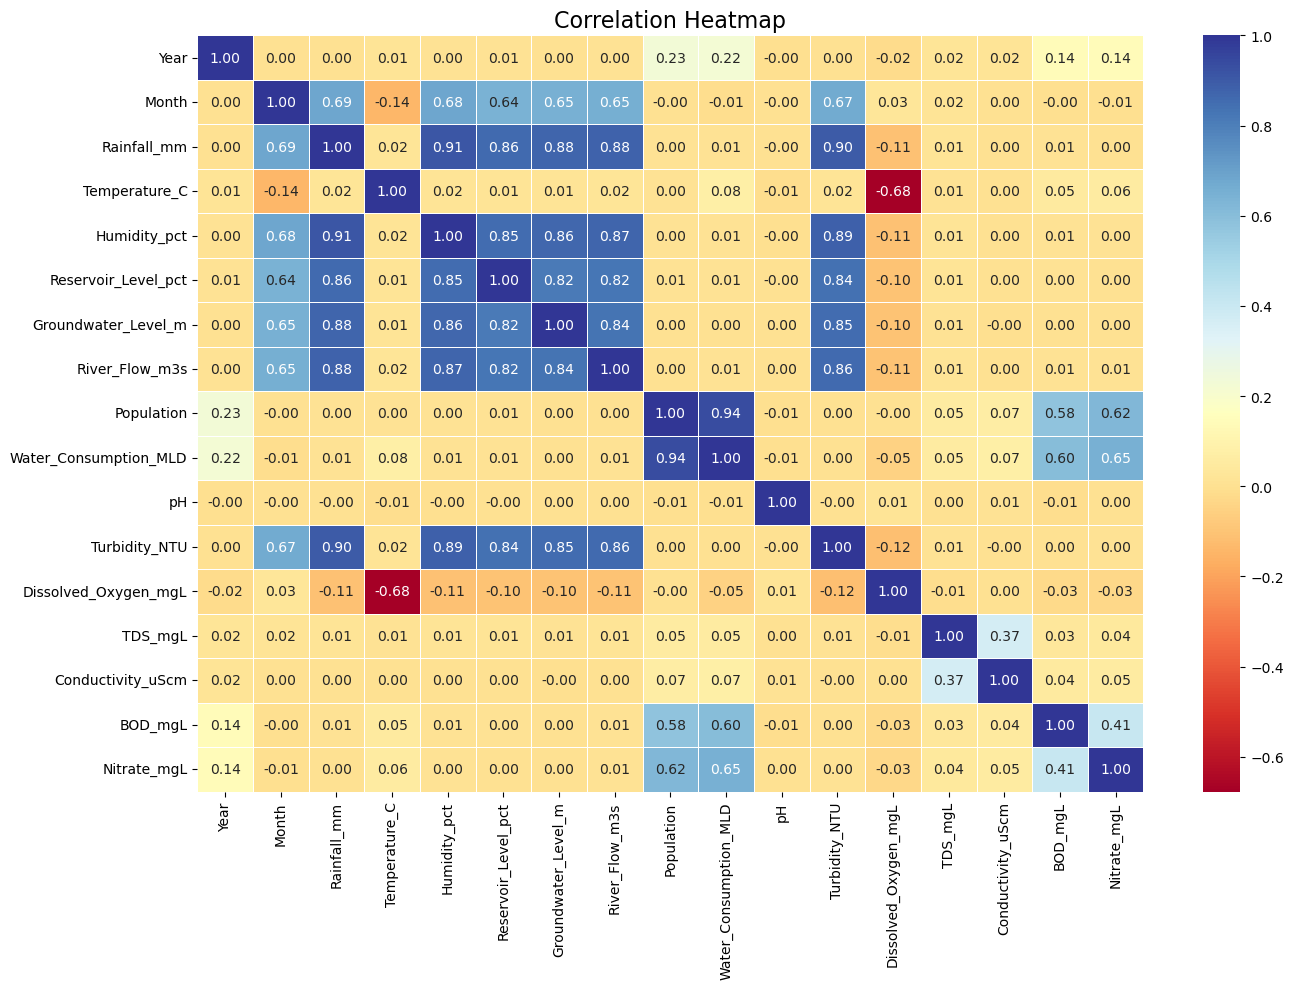

In [12]:
# ==========================================
# Correlation Heatmap
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

# Select only numerical columns
numeric_df = df.select_dtypes(include=["int64", "float64"])

plt.figure(figsize=(14,10))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="RdYlBu",
    linewidths=0.5
)

plt.title("Correlation Heatmap", fontsize=16)
plt.tight_layout()
plt.show()

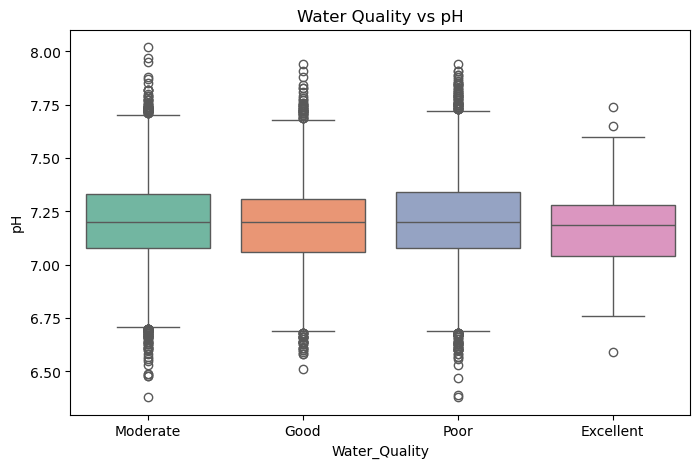

In [13]:
# ==========================================
# Water Quality vs pH
# ==========================================

plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Water_Quality",
    y="pH",
    palette="Set2"
)

plt.title("Water Quality vs pH")
plt.show()

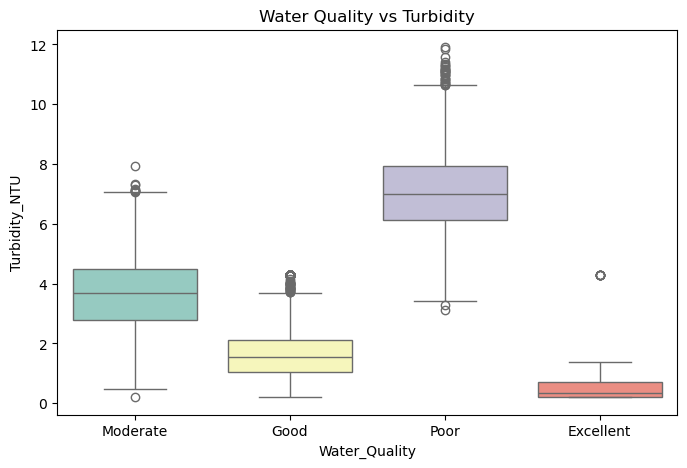

In [14]:
# ==========================================
# Water Quality vs Turbidity
# ==========================================

plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Water_Quality",
    y="Turbidity_NTU",
    palette="Set3"
)

plt.title("Water Quality vs Turbidity")
plt.show()

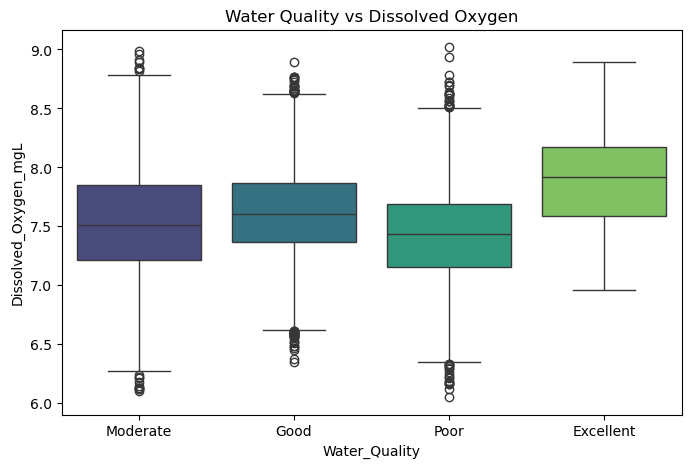

In [15]:
# ==========================================
# Water Quality vs Dissolved Oxygen
# ==========================================

plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Water_Quality",
    y="Dissolved_Oxygen_mgL",
    palette="viridis"
)

plt.title("Water Quality vs Dissolved Oxygen")
plt.show()

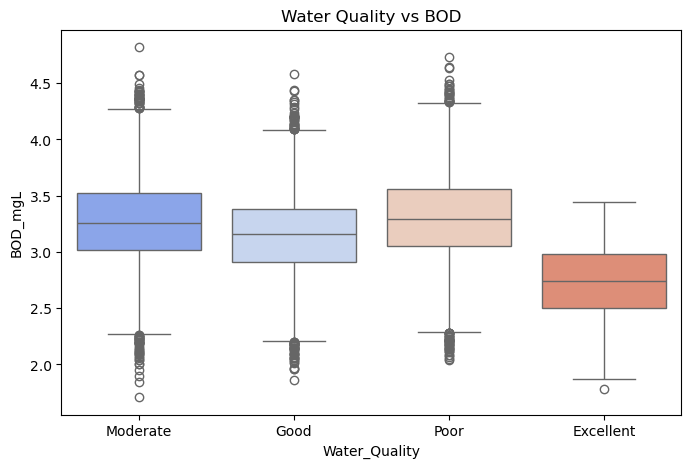

In [16]:
# ==========================================
# Water Quality vs BOD
# ==========================================

plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Water_Quality",
    y="BOD_mgL",
    palette="coolwarm"
)

plt.title("Water Quality vs BOD")
plt.show()

In [17]:
# ==========================================
# Feature Engineering
# ==========================================

# Water Stress Index
df["Water_Stress_Index"] = (
    df["Water_Consumption_MLD"] /
    (df["Reservoir_Level_pct"] + 1)
)

# Pollution Index
df["Pollution_Index"] = (
    df["BOD_mgL"] +
    df["Nitrate_mgL"] +
    df["Turbidity_NTU"]
)

# Water Scarcity Index
df["Water_Scarcity_Index"] = (
    df["Population"] /
    (df["River_Flow_m3s"] + df["Groundwater_Level_m"] + 1)
)

# Per Capita Water Availability
df["Per_Capita_Water"] = (
    df["River_Flow_m3s"] /
    (df["Population"] + 1)
)

# Water Quality Score
df["Water_Quality_Score"] = (
    df["Dissolved_Oxygen_mgL"] +
    df["pH"] -
    df["BOD_mgL"] -
    df["Turbidity_NTU"]
)

print("New Features Added Successfully")

print(df.shape)

df.head()

New Features Added Successfully
(30000, 28)


,Date,State,District,Year,Month,Season,Rainfall_mm,Temperature_C,Humidity_pct,Reservoir_Level_pct,...,Conductivity_uScm,BOD_mgL,Nitrate_mgL,Water_Availability,Water_Quality,Water_Stress_Index,Pollution_Index,Water_Scarcity_Index,Per_Capita_Water,Water_Quality_Score
0,2010-01-01,Telangana,Nizamabad,2010.0,1.0,Winter,29.04,20.63,62.63,37.44,...,400.55,3.24,2.54,Low,Moderate,1.790323,8.56,40626.369996,0.000015,9.12
1,2010-01-01,Karnataka,Mangaluru,2010.0,1.0,Winter,48.32,18.62,62.94,54.38,...,396.51,3.25,2.77,Low,Moderate,1.630733,9.42,56941.874541,0.000012,8.65
2,2010-01-01,Karnataka,Bengaluru,2010.0,1.0,Winter,22.35,21.30,64.34,33.89,...,391.46,2.84,2.46,Low,Good,2.143881,7.21,56248.872180,0.000012,10.27
3,2010-01-01,Tamil Nadu,Madurai,2010.0,1.0,Winter,34.97,21.59,55.44,54.35,...,411.87,3.31,2.57,Low,Good,1.457633,8.55,47900.382542,0.000014,9.71
4,2010-01-01,Karnataka,Mysuru,2010.0,1.0,Winter,44.39,17.25,54.91,46.71,...,394.37,3.51,2.61,Low,Moderate,1.779501,9.63,51205.538822,0.000014,9.02


In [18]:
# ==========================================
# Newly Created Features
# ==========================================

new_features = [
    "Water_Stress_Index",
    "Pollution_Index",
    "Water_Scarcity_Index",
    "Per_Capita_Water",
    "Water_Quality_Score"
]

df[new_features].describe().T

,count,mean,std,min,25%,50%,75%,max
Water_Stress_Index,30000.0,1.697953,0.453843,7.494893e-01,1.353663,1.626309,1.984587,4.155860
Pollution_Index,30000.0,10.508198,2.574348,4.570000e+00,8.290000,10.350000,12.630000,18.370000
Water_Scarcity_Index,30000.0,52155.036386,28053.498965,6.621161e+03,30455.142241,43018.476222,68830.690883,261819.202658
Per_Capita_Water,30000.0,0.000018,0.000010,5.202002e-07,0.000009,0.000016,0.000025,0.000135
Water_Quality_Score,30000.0,7.016251,2.634794,-1.450000e+00,4.820000,7.200000,9.290000,13.050000


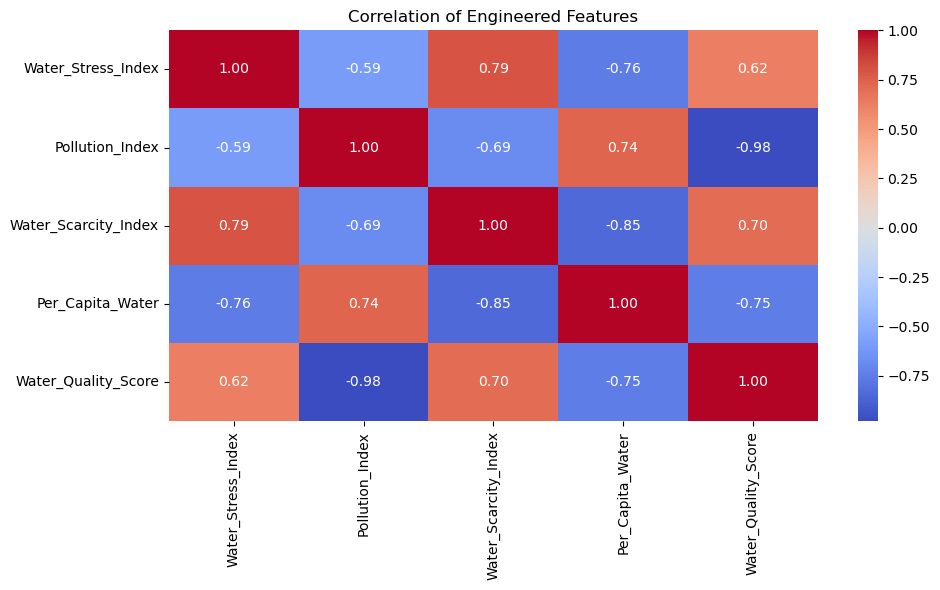

In [19]:
# ==========================================
# Correlation of Engineered Features
# ==========================================

engineered_features = [
    "Water_Stress_Index",
    "Pollution_Index",
    "Water_Scarcity_Index",
    "Per_Capita_Water",
    "Water_Quality_Score"
]

plt.figure(figsize=(10,6))

sns.heatmap(
    df[engineered_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation of Engineered Features")
plt.tight_layout()
plt.show()

In [20]:
# ==========================================
# Separate Features and Target
# ==========================================

target = "Water_Quality"

drop_columns = [
    "Water_Quality",
    "Water_Availability",
    "Date"
]

X = df.drop(columns=drop_columns)

y = df[target]

print("Feature Matrix Shape :", X.shape)
print("Target Shape :", y.shape)

print("\nFeature Columns")
print(X.columns.tolist())

Feature Matrix Shape : (30000, 25)
Target Shape : (30000,)

Feature Columns
['State', 'District', 'Year', 'Month', 'Season', 'Rainfall_mm', 'Temperature_C', 'Humidity_pct', 'Reservoir_Level_pct', 'Groundwater_Level_m', 'River_Flow_m3s', 'Population', 'Water_Consumption_MLD', 'pH', 'Turbidity_NTU', 'Dissolved_Oxygen_mgL', 'TDS_mgL', 'Conductivity_uScm', 'BOD_mgL', 'Nitrate_mgL', 'Water_Stress_Index', 'Pollution_Index', 'Water_Scarcity_Index', 'Per_Capita_Water', 'Water_Quality_Score']


In [21]:
# ==========================================
# Encode Categorical Features
# ==========================================

from sklearn.preprocessing import LabelEncoder

categorical_columns = X.select_dtypes(include="object").columns

print("Categorical Columns")
print(categorical_columns.tolist())

feature_encoders = {}

for column in categorical_columns:

    encoder = LabelEncoder()

    X[column] = encoder.fit_transform(X[column])

    feature_encoders[column] = encoder

print("\nEncoding Completed")

X.head()

Categorical Columns
['State', 'District', 'Season']

Encoding Completed


,State,District,Year,Month,Season,Rainfall_mm,Temperature_C,Humidity_pct,Reservoir_Level_pct,Groundwater_Level_m,...,Dissolved_Oxygen_mgL,TDS_mgL,Conductivity_uScm,BOD_mgL,Nitrate_mgL,Water_Stress_Index,Pollution_Index,Water_Scarcity_Index,Per_Capita_Water,Water_Quality_Score
0,4,18,2010.0,1.0,2,29.04,20.63,62.63,37.44,19.58,...,7.74,228.76,400.55,3.24,2.54,1.790323,8.56,40626.369996,0.000015,9.12
1,1,13,2010.0,1.0,2,48.32,18.62,62.94,54.38,17.32,...,7.83,211.14,396.51,3.25,2.77,1.630733,9.42,56941.874541,0.000012,8.65
2,1,2,2010.0,1.0,2,22.35,21.30,64.34,33.89,16.16,...,7.91,186.84,391.46,2.84,2.46,2.143881,7.21,56248.872180,0.000012,10.27
3,3,12,2010.0,1.0,2,34.97,21.59,55.44,54.35,17.11,...,8.51,201.03,411.87,3.31,2.57,1.457633,8.55,47900.382542,0.000014,9.71
4,1,14,2010.0,1.0,2,44.39,17.25,54.91,46.71,15.88,...,8.82,180.89,394.37,3.51,2.61,1.779501,9.63,51205.538822,0.000014,9.02


In [22]:
# ==========================================
# Encode Target Variable
# ==========================================

target_encoder = LabelEncoder()

y = target_encoder.fit_transform(y)

print("Classes")

for index, name in enumerate(target_encoder.classes_):
    print(index, "=", name)

Classes
0 = Excellent
1 = Good
2 = Moderate
3 = Poor


In [23]:
# ==========================================
# Train Test Split
# ==========================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples :", X_train.shape)
print("Testing Samples :", X_test.shape)

Training Samples : (24000, 25)
Testing Samples : (6000, 25)


In [24]:
# ==========================================
# Feature Scaling
# ==========================================

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Scaling Completed")

print(X_train_scaled.shape)
print(X_test_scaled.shape)

Scaling Completed
(24000, 25)
(6000, 25)


In [25]:
# ==========================================
# Stage-1 Model Training
# ==========================================

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

try:
    from xgboost import XGBClassifier
    xgboost_available = True
except:
    xgboost_available = False

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

stage1_results = []

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "SVM": SVC(kernel="rbf", probability=True, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=42)
}

if xgboost_available:
    models["XGBoost"] = XGBClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=5,
        objective="multi:softprob",
        eval_metric="mlogloss",
        random_state=42
    )

print("Models Loaded Successfully")

Models Loaded Successfully


In [26]:
# ==========================================
# Train and Evaluate Stage-1 Models
# ==========================================

for model_name, model in models.items():

    print("\nTraining:", model_name)

    # Use scaled data for distance/gradient based models
    if model_name in ["Logistic Regression", "SVM", "KNN", "Naive Bayes"]:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    pre = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

    stage1_results.append({
        "Stage": "Stage-1 Original Data",
        "Model": model_name,
        "Accuracy": round(acc, 4),
        "Precision": round(pre, 4),
        "Recall": round(rec, 4),
        "F1 Score": round(f1, 4)
    })

    print("Accuracy:", round(acc, 4))
    print("F1 Score:", round(f1, 4))
    print("Recall:", round(rec,4))
    print("Precision:", round(pre,4))


Training: Logistic Regression
Accuracy: 0.9217
F1 Score: 0.921
Recall: 0.9217
Precision: 0.9215

Training: Decision Tree
Accuracy: 0.9322
F1 Score: 0.9322
Recall: 0.9322
Precision: 0.9323

Training: Random Forest
Accuracy: 0.9448
F1 Score: 0.9441
Recall: 0.9448
Precision: 0.9449

Training: SVM
Accuracy: 0.947
F1 Score: 0.9453
Recall: 0.947
Precision: 0.9437

Training: KNN
Accuracy: 0.8578
F1 Score: 0.8561
Recall: 0.8578
Precision: 0.8544

Training: Naive Bayes
Accuracy: 0.8068
F1 Score: 0.8058
Recall: 0.8068
Precision: 0.8135

Training: AdaBoost
Accuracy: 0.731
F1 Score: 0.7195
Recall: 0.731
Precision: 0.7462

Training: XGBoost
Accuracy: 0.97
F1 Score: 0.9697
Recall: 0.97
Precision: 0.9697


In [27]:
# ==========================================
# Stage-1 Results Table
# ==========================================

stage1_results_df = pd.DataFrame(stage1_results)

stage1_results_df = stage1_results_df.drop_duplicates(
    subset=["Stage", "Model"],
    keep="last"
)

stage1_results_df = stage1_results_df.sort_values(
    by="F1 Score",
    ascending=False
)

stage1_results_df.reset_index(drop=True, inplace=True)

stage1_results_df

,Stage,Model,Accuracy,Precision,Recall,F1 Score
0,Stage-1 Original Data,XGBoost,0.9700,0.9697,0.9700,0.9697
1,Stage-1 Original Data,SVM,0.9470,0.9437,0.9470,0.9453
2,Stage-1 Original Data,Random Forest,0.9448,0.9449,0.9448,0.9441
3,Stage-1 Original Data,Decision Tree,0.9322,0.9323,0.9322,0.9322
4,Stage-1 Original Data,Logistic Regression,0.9217,0.9215,0.9217,0.9210
5,Stage-1 Original Data,KNN,0.8578,0.8544,0.8578,0.8561
6,Stage-1 Original Data,Naive Bayes,0.8068,0.8135,0.8068,0.8058
7,Stage-1 Original Data,AdaBoost,0.7310,0.7462,0.7310,0.7195


In [28]:
from xgboost import XGBClassifier
import joblib
import os

# Train only the best model
best_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=5,
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=42
)

best_model.fit(X_train_scaled, y_train)

# Create Models folder
os.makedirs("Models", exist_ok=True)

# Save model and preprocessing objects
joblib.dump(best_model, "Models/best_water_quality_model.pkl")
joblib.dump(scaler, "Models/scaler.pkl")
joblib.dump(target_encoder, "Models/target_encoder.pkl")
joblib.dump(X.columns.tolist(), "Models/feature_names.pkl")

print("Best model and preprocessing objects saved successfully!")

Best model and preprocessing objects saved successfully!


In [29]:
# ==========================================
# Step 39: Feature Importance Using XGBoost
# ==========================================

from xgboost import XGBClassifier
import pandas as pd

xgb_selector = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=5,
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=42
)

xgb_selector.fit(X_train_scaled, y_train)

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": xgb_selector.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance.head(20)

,Feature,Importance
21,Pollution_Index,0.603564
24,Water_Quality_Score,0.077686
5,Rainfall_mm,0.072360
16,TDS_mgL,0.041697
14,Turbidity_NTU,0.041157
13,pH,0.025709
15,Dissolved_Oxygen_mgL,0.018840
4,Season,0.013111
10,River_Flow_m3s,0.012901
7,Humidity_pct,0.011389


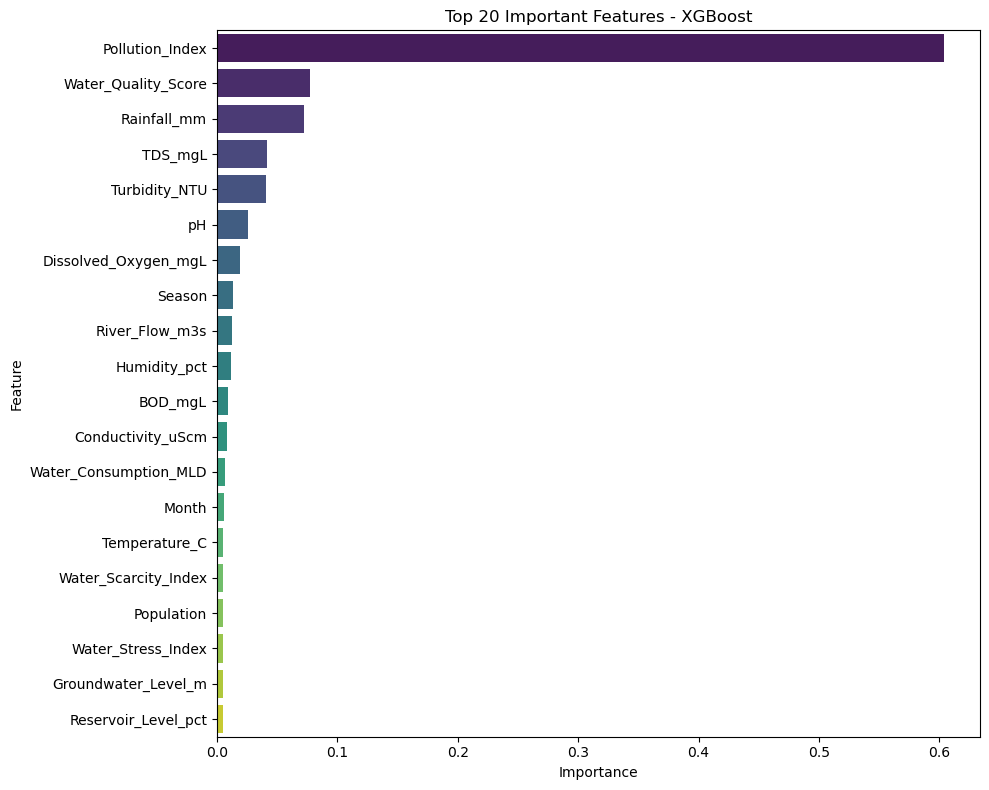

In [30]:
# ==========================================
# Step 40: Plot Top 20 Important Features
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))

sns.barplot(
    data=importance.head(20),
    x="Importance",
    y="Feature",
    palette="viridis"
)

plt.title("Top 20 Important Features - XGBoost")
plt.tight_layout()
plt.show()

In [31]:
# ==========================================
# Step 41: Select Important Features
# ==========================================

selected_features = importance[
    importance["Importance"] > 0.01
]["Feature"].tolist()

print("Selected Features:", len(selected_features))
print(selected_features)

Selected Features: 10
['Pollution_Index', 'Water_Quality_Score', 'Rainfall_mm', 'TDS_mgL', 'Turbidity_NTU', 'pH', 'Dissolved_Oxygen_mgL', 'Season', 'River_Flow_m3s', 'Humidity_pct']


In [32]:
# ==========================================
# Step 42: Selected Feature Dataset
# ==========================================

X_selected = X[selected_features]

print("Original Feature Shape :", X.shape)
print("Selected Feature Shape :", X_selected.shape)

print("\nSelected Features:")
print(X_selected.columns.tolist())

Original Feature Shape : (30000, 25)
Selected Feature Shape : (30000, 10)

Selected Features:
['Pollution_Index', 'Water_Quality_Score', 'Rainfall_mm', 'TDS_mgL', 'Turbidity_NTU', 'pH', 'Dissolved_Oxygen_mgL', 'Season', 'River_Flow_m3s', 'Humidity_pct']


In [33]:
# ==========================================
# Step 43: Train-Test Split - Selected Features
# ==========================================

from sklearn.model_selection import train_test_split

X_train_sel, X_test_sel, y_train_sel, y_test_sel = train_test_split(
    X_selected,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train_sel:", X_train_sel.shape)
print("X_test_sel :", X_test_sel.shape)

X_train_sel: (24000, 10)
X_test_sel : (6000, 10)


In [34]:
# ==========================================
# Step 44: Scaling Selected Features
# ==========================================

from sklearn.preprocessing import StandardScaler

scaler_selected = StandardScaler()

X_train_sel_scaled = scaler_selected.fit_transform(X_train_sel)
X_test_sel_scaled = scaler_selected.transform(X_test_sel)

print("Selected feature scaling completed")

Selected feature scaling completed


XGBoost Selected Features Results
Accuracy : 0.967
Precision: 0.9668
Recall   : 0.967
F1 Score : 0.9668

Classification Report
              precision    recall  f1-score   support

   Excellent       0.79      0.52      0.63        21
        Good       0.96      0.98      0.97      1602
    Moderate       0.96      0.95      0.95      1985
        Poor       0.98      0.98      0.98      2392

    accuracy                           0.97      6000
   macro avg       0.92      0.86      0.88      6000
weighted avg       0.97      0.97      0.97      6000



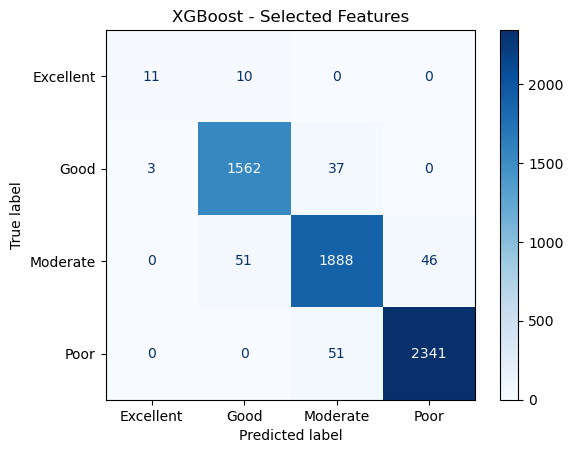

In [35]:
# ==========================================
# Step 45: XGBoost Training - Selected Features
# ==========================================

from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

xgb_selected = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=5,
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=42
)

xgb_selected.fit(X_train_sel_scaled, y_train_sel)

y_pred_sel = xgb_selected.predict(X_test_sel_scaled)

acc = accuracy_score(y_test_sel, y_pred_sel)
pre = precision_score(y_test_sel, y_pred_sel, average="weighted", zero_division=0)
rec = recall_score(y_test_sel, y_pred_sel, average="weighted", zero_division=0)
f1 = f1_score(y_test_sel, y_pred_sel, average="weighted", zero_division=0)

print("XGBoost Selected Features Results")
print("Accuracy :", round(acc, 4))
print("Precision:", round(pre, 4))
print("Recall   :", round(rec, 4))
print("F1 Score :", round(f1, 4))

print("\nClassification Report")
print(classification_report(y_test_sel, y_pred_sel, target_names=target_encoder.classes_))

cm = confusion_matrix(y_test_sel, y_pred_sel)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=target_encoder.classes_
)

disp.plot(cmap="Blues")
plt.title("XGBoost - Selected Features")
plt.show()

In [36]:
# ==========================================
# Step 46: Save Selected Feature Model
# ==========================================

import os
import joblib

os.makedirs("Models", exist_ok=True)

joblib.dump(xgb_selected, "Models/xgboost_selected_features_model.pkl")
joblib.dump(scaler_selected, "Models/scaler_selected.pkl")
joblib.dump(target_encoder, "Models/target_encoder.pkl")
joblib.dump(selected_features, "Models/selected_features.pkl")

print("Selected feature XGBoost model saved successfully.")

Selected feature XGBoost model saved successfully.


In [37]:
# ==========================================
# Step 47: Compare Original vs Selected Features
# ==========================================

comparison_results = pd.DataFrame([
    {
        "Model": "XGBoost - All Features",
        "Accuracy": stage1_results_df[
            stage1_results_df["Model"] == "XGBoost"
        ]["Accuracy"].values[0],
        "Precision": stage1_results_df[
            stage1_results_df["Model"] == "XGBoost"
        ]["Precision"].values[0],
        "Recall": stage1_results_df[
            stage1_results_df["Model"] == "XGBoost"
        ]["Recall"].values[0],
        "F1 Score": stage1_results_df[
            stage1_results_df["Model"] == "XGBoost"
        ]["F1 Score"].values[0]
    },
    {
        "Model": "XGBoost - Selected Features",
        "Accuracy": round(acc, 4),
        "Precision": round(pre, 4),
        "Recall": round(rec, 4),
        "F1 Score": round(f1, 4)
    }
])

comparison_results

,Model,Accuracy,Precision,Recall,F1 Score
0,XGBoost - All Features,0.970,0.9697,0.970,0.9697
1,XGBoost - Selected Features,0.967,0.9668,0.967,0.9668


In [38]:
# ==========================================
# Step 49: Save Final Model - Selected Features
# ==========================================

import os
import joblib

os.makedirs("Models", exist_ok=True)

joblib.dump(xgb_selected, "Models/best_water_quality_model.pkl")
joblib.dump(scaler_selected, "Models/scaler.pkl")
joblib.dump(target_encoder, "Models/target_encoder.pkl")
joblib.dump(selected_features, "Models/feature_names.pkl")

print("Final selected-feature XGBoost model saved successfully!")

Final selected-feature XGBoost model saved successfully!


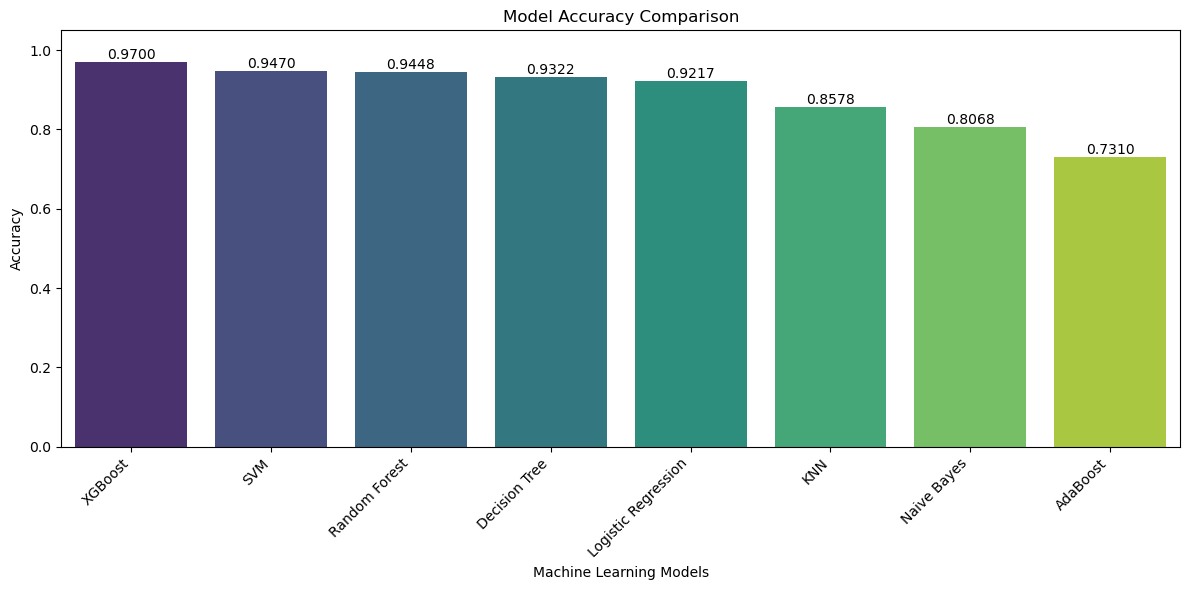

In [39]:
# ==========================================
# Accuracy Comparison Graph by Model
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

accuracy_df = stage1_results_df.sort_values(
    by="Accuracy",
    ascending=False
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=accuracy_df,
    x="Model",
    y="Accuracy",
    palette="viridis"
)

for p in ax.patches:
    ax.annotate(
        f"{p.get_height():.4f}",
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

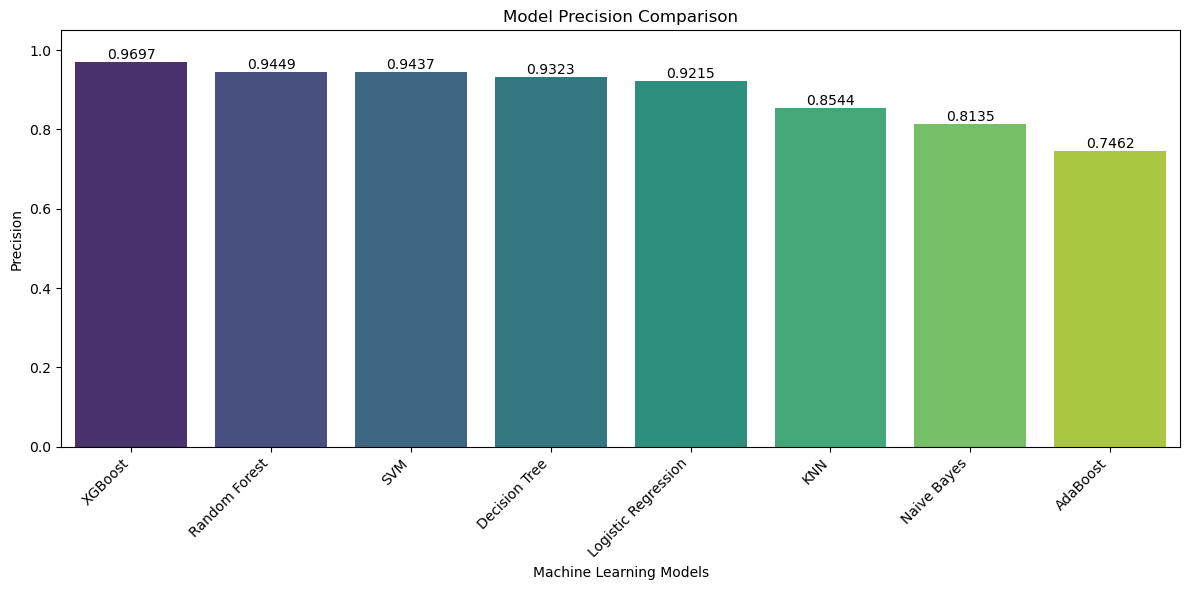

In [40]:
# ==========================================
# Precision Comparison Graph by Model
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

precision_df = stage1_results_df.sort_values(
    by="Precision",
    ascending=False
)

plt.figure(figsize=(12,6))

ax = sns.barplot(
    data=precision_df,
    x="Model",
    y="Precision",
    palette="viridis"
)

for p in ax.patches:
    ax.annotate(
        f"{p.get_height():.4f}",
        (p.get_x() + p.get_width()/2, p.get_height()),
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.title("Model Precision Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Precision")
plt.xticks(rotation=45, ha="right")
plt.ylim(0,1.05)
plt.tight_layout()
plt.show()

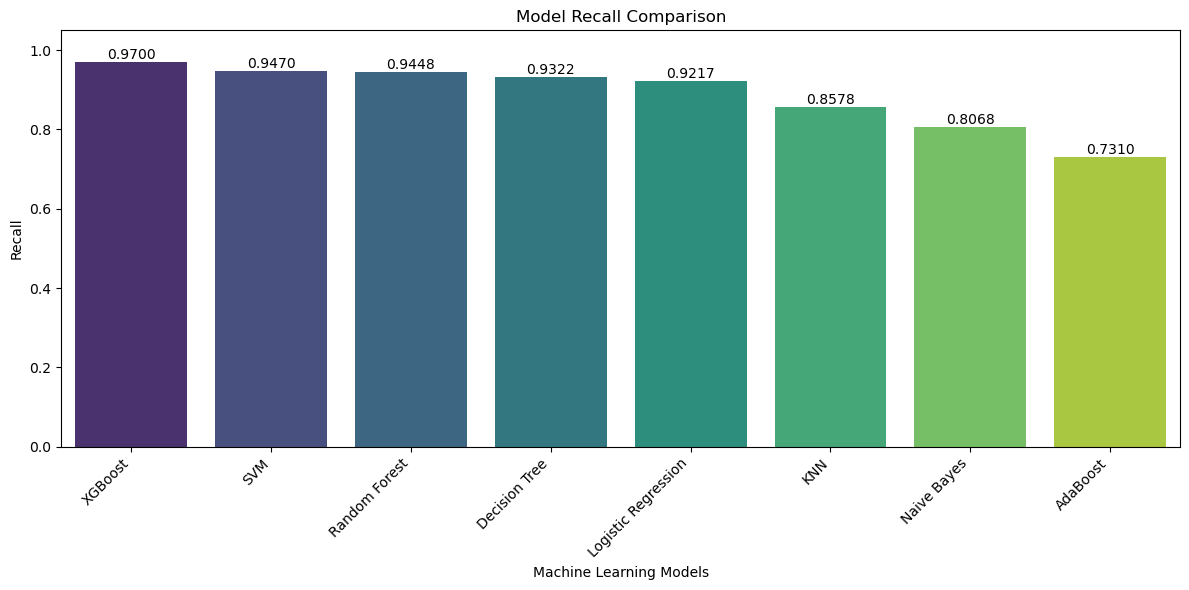

In [41]:
# ==========================================
# Recall Comparison Graph by Model
# ==========================================

recall_df = stage1_results_df.sort_values(
    by="Recall",
    ascending=False
)

plt.figure(figsize=(12,6))

ax = sns.barplot(
    data=recall_df,
    x="Model",
    y="Recall",
    palette="viridis"
)

for p in ax.patches:
    ax.annotate(
        f"{p.get_height():.4f}",
        (p.get_x() + p.get_width()/2, p.get_height()),
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.title("Model Recall Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Recall")
plt.xticks(rotation=45, ha="right")
plt.ylim(0,1.05)
plt.tight_layout()
plt.show()

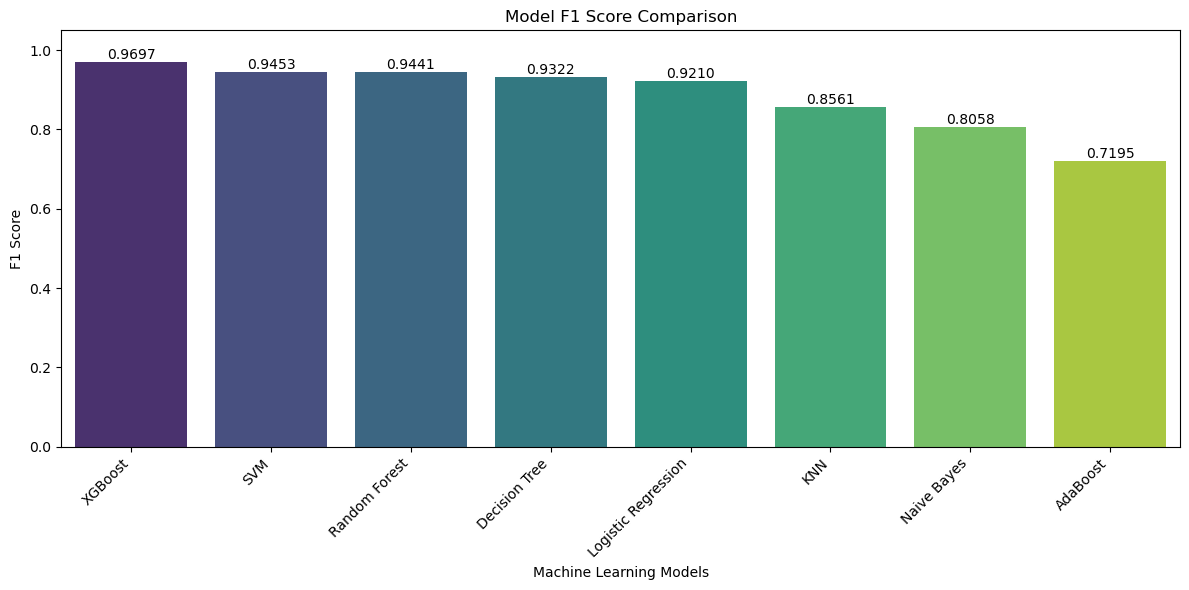

In [42]:
# ==========================================
# F1 Score Comparison Graph by Model
# ==========================================

f1_df = stage1_results_df.sort_values(
    by="F1 Score",
    ascending=False
)

plt.figure(figsize=(12,6))

ax = sns.barplot(
    data=f1_df,
    x="Model",
    y="F1 Score",
    palette="viridis"
)

for p in ax.patches:
    ax.annotate(
        f"{p.get_height():.4f}",
        (p.get_x() + p.get_width()/2, p.get_height()),
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.title("Model F1 Score Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("F1 Score")
plt.xticks(rotation=45, ha="right")
plt.ylim(0,1.05)
plt.tight_layout()
plt.show()

In [43]:
# ==========================================
# AI Recommendation Engine
# ==========================================

def generate_water_recommendation(input_data, predicted_quality):

    recommendations = []
    suitable_uses = []
    avoid_uses = []
    treatment = []

    # ==========================
    # Water Quality Based Rules
    # ==========================

    if predicted_quality == "Excellent":

        suitable_uses.extend([
            "Drinking",
            "Cooking",
            "Hospitals",
            "Laboratories",
            "Food Industry",
            "Aquaculture",
            "Agriculture",
            "Domestic Use"
        ])

        recommendations.append(
            "Water quality is excellent. Continue periodic monitoring."
        )

    elif predicted_quality == "Good":

        suitable_uses.extend([
            "Drinking (after standard treatment)",
            "Cooking",
            "Domestic Use",
            "Agriculture",
            "Aquaculture",
            "Industrial Use"
        ])

        recommendations.append(
            "Maintain current water quality through regular inspections."
        )

    elif predicted_quality == "Moderate":

        suitable_uses.extend([
            "Irrigation",
            "Construction",
            "Industrial Cooling",
            "Washing"
        ])

        avoid_uses.extend([
            "Direct Drinking",
            "Cooking"
        ])

        treatment.extend([
            "Filtration",
            "Chlorination",
            "UV Treatment"
        ])

    elif predicted_quality == "Poor":

        suitable_uses.extend([
            "Construction",
            "Industrial Use",
            "Fire Fighting"
        ])

        avoid_uses.extend([
            "Drinking",
            "Cooking",
            "Agriculture"
        ])

        treatment.extend([
            "Reverse Osmosis",
            "Activated Carbon",
            "Biological Treatment",
            "Aeration"
        ])

    # ==========================
    # Parameter-Based AI Rules
    # ==========================

    if input_data["pH"] < 6.5:
        recommendations.append(
            "Water is acidic. pH correction is recommended."
        )

    elif input_data["pH"] > 8.5:
        recommendations.append(
            "Water is alkaline. Chemical balancing is recommended."
        )

    if input_data["Turbidity_NTU"] > 5:
        recommendations.append(
            "High turbidity detected. Filtration is recommended."
        )

    if input_data["BOD_mgL"] > 4:
        recommendations.append(
            "High Biological Oxygen Demand detected. Organic pollution may be present."
        )

    if input_data["Dissolved_Oxygen_mgL"] < 5:
        recommendations.append(
            "Low dissolved oxygen detected. Aeration is recommended."
        )

    if input_data["Nitrate_mgL"] > 45:
        recommendations.append(
            "High nitrate concentration. Avoid infant consumption."
        )

    if input_data["TDS_mgL"] > 500:
        recommendations.append(
            "High Total Dissolved Solids detected. Water purification is advised."
        )

    return {
        "Suitable Uses": suitable_uses,
        "Avoid Uses": avoid_uses,
        "Treatment": treatment,
        "Recommendations": recommendations
    }

In [44]:
# ==========================================
# Test AI Recommendation Engine
# ==========================================

sample = df.iloc[0]

prediction = "Good"      # Replace later with model prediction

result = generate_water_recommendation(
    sample,
    prediction
)

print("Predicted Water Quality :", prediction)

print("\nSuitable Uses")
for item in result["Suitable Uses"]:
    print("✔", item)

print("\nAvoid Uses")
for item in result["Avoid Uses"]:
    print("✖", item)

print("\nTreatment")
for item in result["Treatment"]:
    print("•", item)

print("\nAI Recommendations")
for item in result["Recommendations"]:
    print("•", item)

Predicted Water Quality : Good

Suitable Uses
✔ Drinking (after standard treatment)
✔ Cooking
✔ Domestic Use
✔ Agriculture
✔ Aquaculture
✔ Industrial Use

Avoid Uses

Treatment

AI Recommendations
• Maintain current water quality through regular inspections.


# XAI-LIME

Test Instance     : 5
Actual Class      : Good
Predicted Class   : Good
Prediction Prob.  : 1.0

LIME Local Feature Contributions
Pollution_Index <= -0.86                      0.481940
Water_Quality_Score > 0.86                    0.358087
TDS_mgL <= -0.43                              0.180595
Turbidity_NTU <= -0.89                        0.083891
River_Flow_m3s <= -0.91                       0.058060
pH <= -0.67                                   0.056709
Rainfall_mm <= -1.02                          0.021052
-1.25 < Season <= -0.09                       0.018486
Humidity_pct <= -0.92                         0.014109
-0.70 < Dissolved_Oxygen_mgL <= -0.00         0.003655


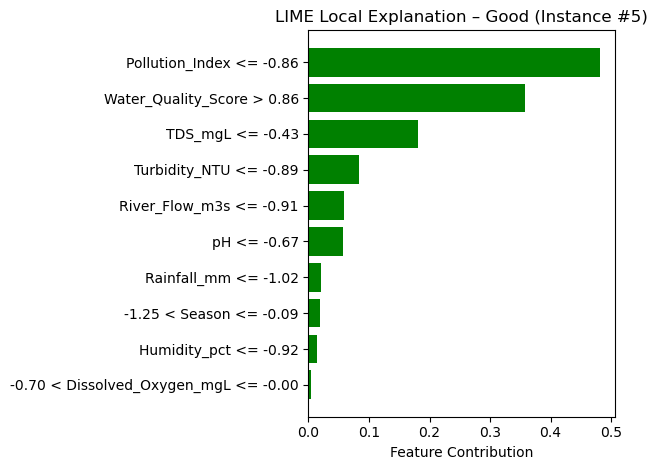

In [45]:
# ==========================================
# LIME Local Explanation - Final XGBoost Model
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from lime.lime_tabular import LimeTabularExplainer

# LIME must use the same scaled data used to train xgb_selected
lime_explainer = LimeTabularExplainer(
    training_data=X_train_sel_scaled,
    feature_names=selected_features,
    class_names=target_encoder.classes_.tolist(),
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

# Select one test instance
instance_index = 5
instance_scaled = X_test_sel_scaled[instance_index]

# Generate local explanation
lime_explanation = lime_explainer.explain_instance(
    data_row=instance_scaled,
    predict_fn=xgb_selected.predict_proba,
    num_features=min(10, len(selected_features)),
    num_samples=1000,
    top_labels=1
)

# Model prediction
predicted_class = int(
    xgb_selected.predict(instance_scaled.reshape(1, -1))[0]
)

predicted_label = target_encoder.inverse_transform(
    [predicted_class]
)[0]

prediction_probability = xgb_selected.predict_proba(
    instance_scaled.reshape(1, -1)
)[0][predicted_class]

print("Test Instance     :", instance_index)
print("Actual Class      :", target_encoder.inverse_transform(
    [y_test_sel[instance_index]]
)[0])
print("Predicted Class   :", predicted_label)
print("Prediction Prob.  :", round(float(prediction_probability), 4))

# Print LIME feature contributions
lime_table = lime_explanation.as_list(label=predicted_class)

print("\nLIME Local Feature Contributions")

for feature, contribution in lime_table:
    print(f"{feature:45s} {contribution:.6f}")

# Display standard LIME local explanation
lime_explanation.show_in_notebook(
    show_table=True,
    show_all=False
)

# Display LIME contribution graph
figure = lime_explanation.as_pyplot_figure(
    label=predicted_class
)

plt.title(
    f"LIME Local Explanation – {predicted_label} "
    f"(Instance #{instance_index})"
)
plt.xlabel("Feature Contribution")
plt.tight_layout()
plt.show()

# XAI-SHAPE

  0%|          | 0/100 [00:00<?, ?it/s]

Number of classes: 4
SHAP shape: (100, 10, 4)
Displaying SHAP for class: Good


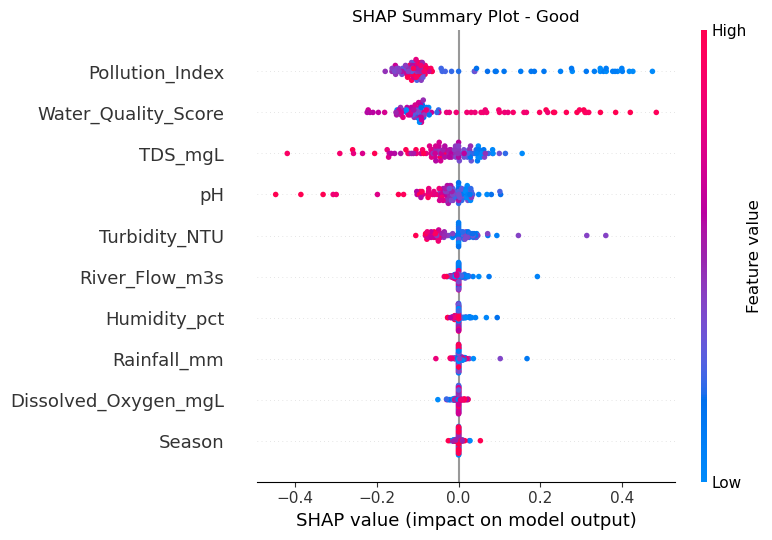

In [48]:
# ==========================================
# SHAP Summary Plot - Final XGBoost Model
# ==========================================

import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

# Convert selected scaled training data to DataFrame
X_train_shap = pd.DataFrame(
    X_train_sel_scaled,
    columns=selected_features
)

# Small background sample for KernelExplainer
X_background = shap.sample(
    X_train_shap,
    20,
    random_state=42
)

# Samples to explain
X_explain = shap.sample(
    X_train_shap,
    100,
    random_state=1
)

# SHAP explainer for multiclass classification
explainer = shap.KernelExplainer(
    xgb_selected.predict_proba,
    X_background
)

# Calculate SHAP values
shap_values = explainer.shap_values(
    X_explain,
    nsamples=100
)

print("Number of classes:", len(target_encoder.classes_))
print("SHAP shape:", np.array(shap_values).shape)

# Select the class to display
class_index = 1

print(
    "Displaying SHAP for class:",
    target_encoder.classes_[class_index]
)

# Handle different SHAP output formats
if isinstance(shap_values, list):

    class_shap_values = shap_values[class_index]

else:
    shap_array = np.asarray(shap_values)

    if shap_array.ndim == 3:
        class_shap_values = shap_array[:, :, class_index]
    else:
        class_shap_values = shap_array

# SHAP summary plot
shap.summary_plot(
    class_shap_values,
    X_explain,
    feature_names=selected_features,
    plot_type="dot",
    show=False
)

plt.title(
    f"SHAP Summary Plot - "
    f"{target_encoder.classes_[class_index]}"
)

plt.tight_layout()
plt.show()

  0%|          | 0/1 [00:00<?, ?it/s]

Sample Index    : 0
Predicted Class : Moderate


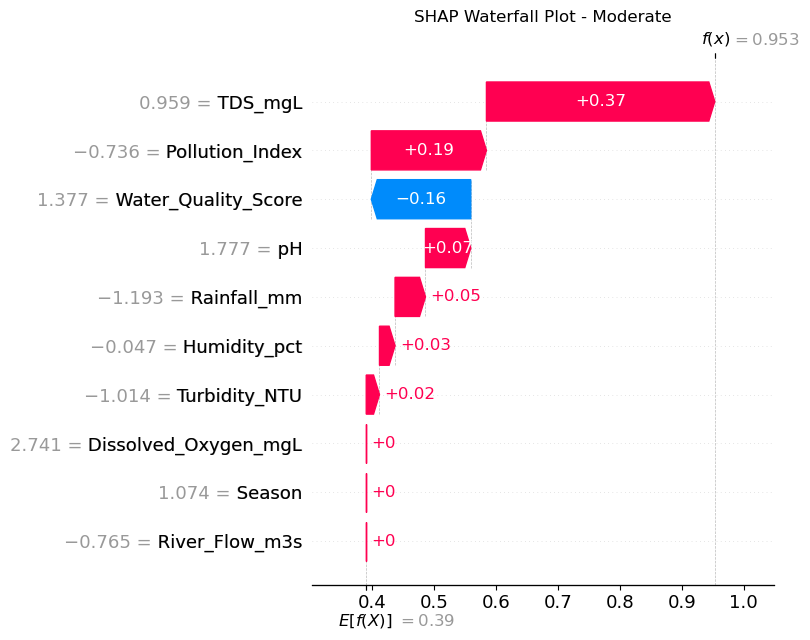

In [49]:
# ==========================================
# SHAP Waterfall Plot - Single Test Instance
# ==========================================

import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

# Selected and scaled training data
X_train_df = pd.DataFrame(
    X_train_sel_scaled,
    columns=selected_features
)

# Background data
X_background = shap.sample(
    X_train_df,
    10,
    random_state=42
)

# Select one instance
sample_index = 0

X_single = pd.DataFrame(
    X_test_sel_scaled[sample_index].reshape(1, -1),
    columns=selected_features
)

# Predicted class for this instance
predicted_class = int(
    xgb_selected.predict(X_single)[0]
)

predicted_label = target_encoder.inverse_transform(
    [predicted_class]
)[0]

# Kernel SHAP for classification
explainer = shap.KernelExplainer(
    xgb_selected.predict_proba,
    X_background
)

# SHAP values for the selected instance
shap_values_single = explainer.shap_values(
    X_single,
    nsamples=100
)

# Handle different SHAP output formats
if isinstance(shap_values_single, list):

    values = np.asarray(
        shap_values_single[predicted_class]
    )[0]

    base_value = np.asarray(
        explainer.expected_value
    )[predicted_class]

else:
    shap_array = np.asarray(shap_values_single)

    if shap_array.ndim == 3:
        values = shap_array[0, :, predicted_class]
        base_value = np.asarray(
            explainer.expected_value
        )[predicted_class]
    else:
        values = shap_array[0]
        base_value = np.asarray(
            explainer.expected_value
        ).reshape(-1)[0]

# Create SHAP Explanation object
shap_exp = shap.Explanation(
    values=values,
    base_values=base_value,
    data=X_single.iloc[0].values,
    feature_names=selected_features
)

print("Sample Index    :", sample_index)
print("Predicted Class :", predicted_label)

# Waterfall plot
shap.plots.waterfall(
    shap_exp,
    max_display=12,
    show=False
)

plt.title(
    f"SHAP Waterfall Plot - {predicted_label}"
)

plt.tight_layout()
plt.show()

# XAI-PDP

PDP class: Good
PDP features: ['Pollution_Index', 'Water_Quality_Score', 'Rainfall_mm']


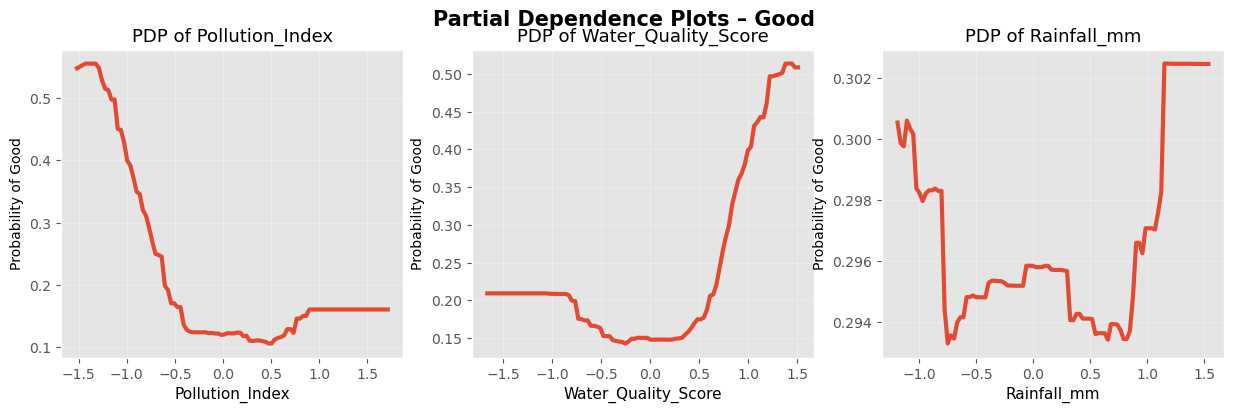

In [53]:
# ==========================================
# Partial Dependence Plots - Final XGBoost
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import partial_dependence

plt.style.use("ggplot")

# Create DataFrame using the selected scaled features
X_train_df = pd.DataFrame(
    X_train_sel_scaled,
    columns=selected_features
)

# Select the first three features from your final selected features
features = selected_features[:3]

# Select class to explain
class_index = 1

print("PDP class:", target_encoder.classes_[class_index])
print("PDP features:", features)

# Use a smaller sample for faster execution
X_small = X_train_df.sample(
    n=min(300, len(X_train_df)),
    random_state=42
)

fig, axes = plt.subplots(
    1,
    len(features),
    figsize=(15, 4)
)

for i, feature in enumerate(features):

    pd_result = partial_dependence(
        estimator=xgb_selected,
        X=X_small,
        features=[feature],
        response_method="predict_proba",
        kind="average"
    )

    x = pd_result["values"][0]
    average = np.asarray(pd_result["average"])

    # Multiclass output
    if average.shape[0] > 1:
        y = average[class_index]

    # Binary or single-output format
    else:
        y = average[0]

    axes[i].plot(
        x,
        y,
        linewidth=3
    )

    axes[i].set_title(
        f"PDP of {feature}",
        fontsize=13
    )

    axes[i].set_xlabel(
        feature,
        fontsize=11
    )

    axes[i].set_ylabel(
        f"Probability of {target_encoder.classes_[class_index]}",
        fontsize=10
    )

    axes[i].grid(alpha=0.3)

plt.suptitle(
    f"Partial Dependence Plots – {target_encoder.classes_[class_index]}",
    fontsize=15,
    fontweight="bold"
)


plt.show()